# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Karthick-177/Flyrank-ML-Internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

**Research question:** Which pages should a content team review for a refresh first, based on their observed performance and freshness?

**Decision supported:** Which pages to refresh now and which can wait.

**Who acts on it:** The SEO or content team, who use the ranked list to choose where to spend limited editing time.

**Cost of a wrong call:** Refreshing the wrong pages wastes effort. Missing an important page may mean traffic keeps declining.

**Scope:** This work gives observed, directional, decision-support rankings. It does not prove that a refresh will improve traffic or rankings.

In [11]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("Lane: Refresh / Content Opportunity Scoring")

Lane: Refresh / Content Opportunity Scoring


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

**Release:** FlyRank ML Internship starter dataset (anonymized content-refresh table).

**Table and grain:** One row per pseudonymized content item, 30,000 rows and 44 columns, with trailing-90-day metrics.

**Excluded and why:**
- `content_id` and `client_id` are pseudonyms. They are used only for grouping and splitting, never as features.
- `trend_direction` and `trend_pct` are never used as features, because the label is derived from them (leakage).
- Rows with `avg_position = 0` are treated as "no data", not as a real rank.

**Public-safe:** No client names, domains, URLs, or private queries are used anywhere.

In [12]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
!git clone https://github.com/Karthick-177/Flyrank-ML-Internship.git repo 2>/dev/null
%cd repo
import pandas as pd

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print("Rows, columns:", df.shape)
print("Clients:", df["client_id"].nunique())
print("Rows with avg_position = 0 (no data):", (df["avg_position"] == 0).sum())

/content/repo/repo
Rows, columns: (30000, 44)
Clients: 32
Rows with avg_position = 0 (no data): 1205


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Baseline:** a transparent rule score = days_since_last_update × impressions_90d, with no fitted weights. It is the same "stale but visible" idea as the earlier baseline, so older pages with more visibility rank higher.

**Model:** a gradient boosting classifier trained on the grouped training split, compared with the baseline on the same held-out clients.

**Metrics:** ROC-AUC (ranking quality) and precision@K, always shown next to the base rate. The base rate is 0.617 on test.

**Label:** `needs_refresh = 1` if `trend_direction == "down"` (impressions fell more than 20% in the last 30 days vs the 30 days before), otherwise 0.

**Population:** Only pages that had impressions in the earlier window. Pages marked `new` or `flat` have no earlier baseline, so they cannot decline and are excluded.

**Leakage rule:** `trend_direction`, `trend_pct`, and every `*_last_30d` / `*_prev_30d` column are excluded from features, because the label is computed from those windows. IDs are used only for grouping.

**Honest framing:** This label is an observed proxy for "page is losing visibility". It is decision-support, not proof that a refresh would fix a decline.

**Features:** content age and days since last update, word count, search volume, competition, CPC, 90-day impressions/clicks/sessions/pageviews, CTR, average position (0 treated as missing), engagement rate, content type, and search intent.

**Missing values:** missing numeric values are filled with the median, and `has_` flags mark where data was absent, since missingness follows content type.

**Validation design:** grouped split by `client_id` (about 80% of clients for training, 20% for testing). Pages from one client never appear in both sets, so the model is tested on clients it has not seen.


In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
model_df = df[~df["trend_direction"].isin(["new", "flat"])].copy()
model_df["needs_refresh"] = (model_df["trend_direction"] == "down").astype(int)

print("Pages kept:", len(model_df), "of", len(df))
print("Base rate (share labeled needs_refresh):", round(model_df["needs_refresh"].mean(), 3))
print(model_df["trend_direction"].value_counts())

Pages kept: 26612 of 30000
Base rate (share labeled needs_refresh): 0.611
trend_direction
down      16262
stable     5962
up         4388
Name: count, dtype: int64


In [14]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

num_cols = ["content_age_days","days_since_last_update","word_count","search_volume",
            "competition","cpc","impressions_90d","clicks_90d","sessions_90d",
            "pageviews_90d","ctr","avg_position","engagement_rate"]
cat_cols = ["content_type","main_intent"]

X = model_df[num_cols + cat_cols].copy()
X["avg_position"] = X["avg_position"].replace(0, np.nan)
for c in ["word_count","search_volume","avg_position"]:
    X["has_" + c] = X[c].notna().astype(int)
X[num_cols] = X[num_cols].fillna(X[num_cols].median())
X = pd.get_dummies(X, columns=cat_cols, dummy_na=True)
y = model_df["needs_refresh"]
groups = model_df["client_id"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train clients:", groups.iloc[train_idx].nunique(), "| Test clients:", groups.iloc[test_idx].nunique())
print("Base rate train:", round(y_train.mean(),3), "| test:", round(y_test.mean(),3))
print("Client overlap:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Train rows: 21514 | Test rows: 5098
Train clients: 24 | Test clients: 7
Base rate train: 0.61 | test: 0.617
Client overlap: 0


In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import numpy as np

def precision_at_k(scores, labels, k):
    order = np.argsort(-np.asarray(scores))
    return np.asarray(labels)[order[:k]].mean()

# Baseline: transparent rule, no fitting
base_score = X_test["days_since_last_update"] * X_test["impressions_90d"]

# Model
clf = HistGradientBoostingClassifier(random_state=42)
clf.fit(X_train, y_train)
model_score = clf.predict_proba(X_test)[:, 1]

print("Base rate (test):", round(y_test.mean(), 3))
print("ROC-AUC  baseline:", round(roc_auc_score(y_test, base_score), 3), "| model:", round(roc_auc_score(y_test, model_score), 3))
for k in [100, 500, 1000]:
    print(f"precision@{k}  baseline:", round(precision_at_k(base_score, y_test, k), 3),
          "| model:", round(precision_at_k(model_score, y_test, k), 3))

Base rate (test): 0.617
ROC-AUC  baseline: 0.365 | model: 0.626
precision@100  baseline: 0.35 | model: 0.95
precision@500  baseline: 0.396 | model: 0.86
precision@1000  baseline: 0.411 | model: 0.787


In [16]:
risky = ["impressions_90d","clicks_90d","sessions_90d","pageviews_90d","ctr","avg_position","engagement_rate",
         "has_avg_position"]
safe_cols = [c for c in X_train.columns if c not in risky]

clf2 = HistGradientBoostingClassifier(random_state=42)
clf2.fit(X_train[safe_cols], y_train)
score2 = clf2.predict_proba(X_test[safe_cols])[:, 1]

print("Base rate (test):", round(y_test.mean(), 3))
print("ROC-AUC  full model:", round(roc_auc_score(y_test, model_score), 3),
      "| without 90d activity features:", round(roc_auc_score(y_test, score2), 3))
for k in [100, 500, 1000]:
    print(f"precision@{k}  full:", round(precision_at_k(model_score, y_test, k), 3),
          "| without 90d:", round(precision_at_k(score2, y_test, k), 3))

Base rate (test): 0.617
ROC-AUC  full model: 0.626 | without 90d activity features: 0.597
precision@100  full: 0.95 | without 90d: 0.88
precision@500  full: 0.86 | without 90d: 0.76
precision@1000  full: 0.787 | without 90d: 0.748


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

**Headline result:** On 7 held-out clients, the model without 90-day activity features reached precision@100 of 0.88 against a base rate of 0.617. The transparent baseline (days since update × impressions) ranked below chance (ROC-AUC 0.365).

**Overall ranking is modest:** ROC-AUC is 0.597, so the model is strongest at the top of the list and weak across the full list.

**Leakage note:** The 90-day activity features raised precision@100 to 0.95, but they overlap the 30-day windows used to build the label, so they are excluded from the headline model.

   K  Baseline  Model (safe features)  Base rate
 100     0.350                  0.880      0.617
 500     0.396                  0.760      0.617
1000     0.411                  0.748      0.617
ROC-AUC  baseline: 0.365 | model (safe): 0.597


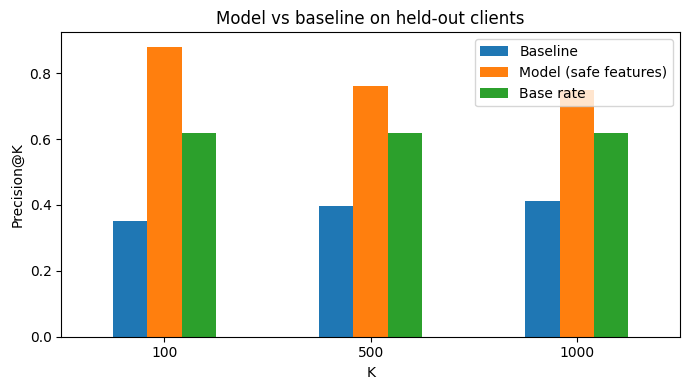

Clients in model's top 100: 6 of 7


In [17]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import matplotlib.pyplot as plt
import os

ks = [100, 500, 1000]
rows = []
for k in ks:
    rows.append({"K": k,
                 "Baseline": precision_at_k(base_score, y_test, k),
                 "Model (safe features)": precision_at_k(score2, y_test, k),
                 "Base rate": y_test.mean()})
res = pd.DataFrame(rows).round(3)
print(res.to_string(index=False))
print("ROC-AUC  baseline:", round(roc_auc_score(y_test, base_score), 3),
      "| model (safe):", round(roc_auc_score(y_test, score2), 3))

os.makedirs("work/outputs", exist_ok=True)
ax = res.set_index("K")[["Baseline", "Model (safe features)", "Base rate"]].plot(kind="bar", figsize=(7, 4))
ax.set_ylabel("Precision@K")
ax.set_title("Model vs baseline on held-out clients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("work/outputs/results_precision_at_k.png", dpi=150)
plt.show()

top100 = model_df.iloc[test_idx].iloc[np.argsort(-score2)[:100]]
print("Clients in model's top 100:", top100["client_id"].nunique(), "of", groups.iloc[test_idx].nunique())

## 5. Limitations

*What this work cannot claim.*

- **Weak explanations.** In the top 50, 40 pages received the generic `monitor` code, so the reason codes explain only a minority of the model's picks.
- **Clustered picks.** Several top-ranked pages have near-identical properties, so the list may contain batches of similar pages rather than 50 independent cases.

**What this shows (observed, directional):** On 7 held-out clients, a model using page properties ranked pages that later showed an impressions drop (more than 20%) better than a transparent "stale but visible" rule did. At the top of the list it was right about 88 of 100 times, against a 61.7% base rate.

**Limitations:**
- **Proxy label.** "needs_refresh" means impressions fell more than 20% over 30 days. It does not mean a refresh would fix the page. Seasonality, algorithm changes or tracking changes can also cause drops.
- **Modest overall ranking.** ROC-AUC is 0.597. The model is useful at the top of the list, not across all pages.
- **Small test set.** Only 7 held-out clients and a single split, so results may change with a different split.
- **Possible residual leakage.** The 90-day activity features overlap the label window and were excluded. The remaining features were not proven free of leakage, only checked with an ablation.
- **Baseline.** The rule scored below chance here. It was not tuned, because tuning it on test data would be unfair.
- **Snapshot data.** One trailing-90-day starter snapshot. There is no time-aware validation.

**What this does not claim:** It does not prove that refreshing a page improves traffic or rankings, and it says nothing about how any search engine works. It is decision-support for prioritizing pages for review.

In [18]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("Limitations reviewed: proxy label, modest ROC-AUC, 7 test clients, possible residual leakage, untuned baseline, snapshot data")

Limitations reviewed: proxy label, modest ROC-AUC, 7 test clients, possible residual leakage, untuned baseline, snapshot data


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

**How to read this list:** Pages are ranked by the safe-feature model's probability that impressions will fall more than 20% over 30 days. The top of the list is where the model was most reliable on held-out clients.

**Actions (decision-support, not a guarantee):**
- `review_stale_content`: page is old and not recently updated. Check whether the content is still accurate.
- `review_low_engagement_page`: page has thin content. Check whether it answers the search intent.
- `monitor`: model flags a possible decline but no clear content cause is visible. Watch it before spending effort.

Reason codes come from simple, checkable thresholds on page properties. A person should confirm each page before acting.

In [19]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
rec = model_df.iloc[test_idx].copy()
rec["risk_score"] = score2
rec = rec.sort_values("risk_score", ascending=False).head(50)

age_cut = model_df["days_since_last_update"].quantile(0.75)
wc_cut = model_df["word_count"].quantile(0.25)

def reason(row):
    if row["days_since_last_update"] >= age_cut:
        return "review_stale_content"
    if pd.notna(row["word_count"]) and row["word_count"] <= wc_cut:
        return "review_low_engagement_page"
    return "monitor"

rec["action_code"] = rec.apply(reason, axis=1)
rec["rank"] = range(1, len(rec) + 1)
cols = ["rank", "content_type", "days_since_last_update", "word_count", "risk_score", "action_code"]
os.makedirs("work/outputs", exist_ok=True)
rec[cols].to_csv("work/outputs/ranked_recommendations.csv", index=False)

print("Stale cutoff (days):", round(age_cut), "| thin-content cutoff (words):", round(wc_cut))
print(rec["action_code"].value_counts())
print(rec[cols].head(10).to_string(index=False))

Stale cutoff (days): 104 | thin-content cutoff (words): 2523
action_code
monitor                       40
review_stale_content           9
review_low_engagement_page     1
Name: count, dtype: int64
 rank    content_type  days_since_last_update  word_count  risk_score                action_code
    1  feedly article                       8      4412.0    0.951770                    monitor
    2  feedly article                       8      4138.0    0.950778                    monitor
    3  feedly article                       8      4389.0    0.949230                    monitor
    4 keyword article                     106      2691.0    0.943220       review_stale_content
    5 keyword article                     106      2898.0    0.943220       review_stale_content
    6 keyword article                     106      3044.0    0.943220       review_stale_content
    7 keyword article                     106      2911.0    0.943220       review_stale_content
    8 keyword article     

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

In [20]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("Artifacts saved for the paper:")
for f in sorted(os.listdir("work/outputs")):
    print(" -", f)

Artifacts saved for the paper:
 - ranked_recommendations.csv
 - results_precision_at_k.png


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.